In [1]:
# ==========================================
# STEP 1: UPLOAD AND EXTRACT THE DATASET
# ==========================================

from google.colab import files
import zipfile
import os

print("Upload your unemployment dataset ZIP file.")

uploaded = files.upload()

# Create a folder for the datasets
os.makedirs("data", exist_ok=True)

# Extract uploaded ZIP files
for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall("data")

print("\nDataset extraction completed!")

# Display extracted files
for root, dirs, filenames in os.walk("data"):
    for filename in filenames:
        print(os.path.join(root, filename))

Upload your unemployment dataset ZIP file.


Saving archive.zip to archive.zip

Dataset extraction completed!
data/Unemployment in India.csv
data/Unemployment_Rate_upto_11_2020.csv


In [2]:
# ==========================================
# STEP 2: DATA CLEANING AND VALIDATION
# ==========================================

import pandas as pd
import numpy as np

# Load both datasets
df_area = pd.read_csv("data/Unemployment in India.csv")
df_states = pd.read_csv("data/Unemployment_Rate_upto_11_2020.csv")

# Standardize column names by removing leading/trailing spaces
df_area.columns = df_area.columns.str.strip()
df_states.columns = df_states.columns.str.strip()

# Remove completely empty rows
df_area.dropna(how="all", inplace=True)
df_states.dropna(how="all", inplace=True)

# Convert date columns to datetime
df_area["Date"] = pd.to_datetime(
    df_area["Date"],
    dayfirst=True,
    errors="coerce"
)

df_states["Date"] = pd.to_datetime(
    df_states["Date"],
    dayfirst=True,
    errors="coerce"
)

# Convert numeric columns safely
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_columns:
    df_area[col] = pd.to_numeric(df_area[col], errors="coerce")
    df_states[col] = pd.to_numeric(df_states[col], errors="coerce")

# Remove rows missing essential analysis fields
required_area = [
    "Region", "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "Area"
]

required_states = [
    "Region", "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

df_area.dropna(subset=required_area, inplace=True)
df_states.dropna(subset=required_states, inplace=True)

# Remove exact duplicate records
df_area.drop_duplicates(inplace=True)
df_states.drop_duplicates(inplace=True)

# Sort by region and date
df_area.sort_values(["Region", "Date"], inplace=True)
df_states.sort_values(["Region", "Date"], inplace=True)

# Reset row indexes
df_area.reset_index(drop=True, inplace=True)
df_states.reset_index(drop=True, inplace=True)

print("=" * 60)
print("DATA CLEANING SUMMARY")
print("=" * 60)

print("\nRural/Urban dataset shape:", df_area.shape)
print("State dataset shape:", df_states.shape)

print("\nRural/Urban date range:")
print(df_area["Date"].min(), "to", df_area["Date"].max())

print("\nState dataset date range:")
print(df_states["Date"].min(), "to", df_states["Date"].max())

print("\nAreas available:")
print(df_area["Area"].value_counts())

print("\nMissing values after cleaning:")
print("\nRural/Urban dataset:")
print(df_area.isnull().sum())

print("\nState dataset:")
print(df_states.isnull().sum())

print("\nFirst five cleaned records:")
display(df_area.head())

DATA CLEANING SUMMARY

Rural/Urban dataset shape: (740, 7)
State dataset shape: (267, 9)

Rural/Urban date range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

State dataset date range:
2020-01-31 00:00:00 to 2020-10-31 00:00:00

Areas available:
Area
Urban    381
Rural    359
Name: count, dtype: int64

Missing values after cleaning:

Rural/Urban dataset:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

State dataset:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                      

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban
2,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
3,Andhra Pradesh,2019-06-30,Monthly,3.80,4824630.0,36.76,Urban
4,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural


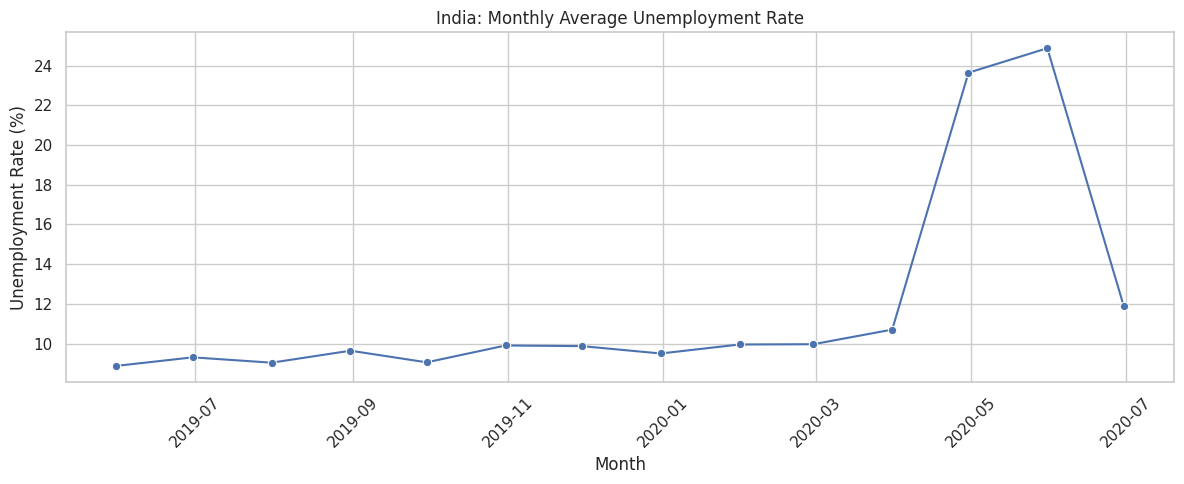

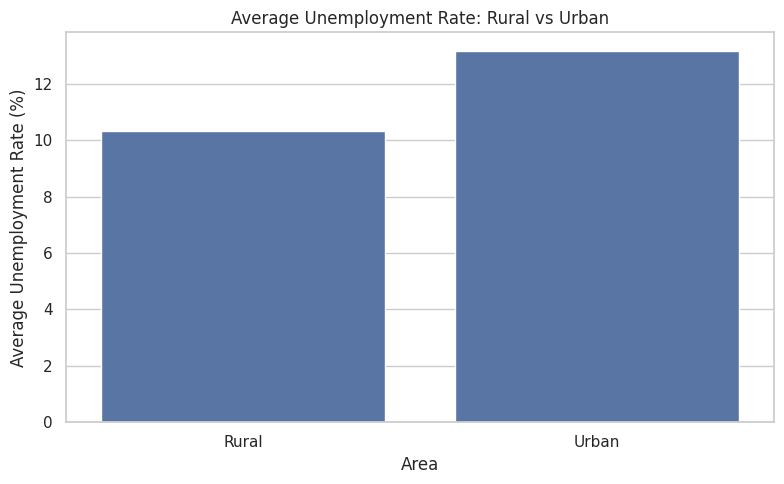

Rural/Urban comparison:


,Area,Estimated Unemployment Rate (%)
0,Rural,10.32
1,Urban,13.17


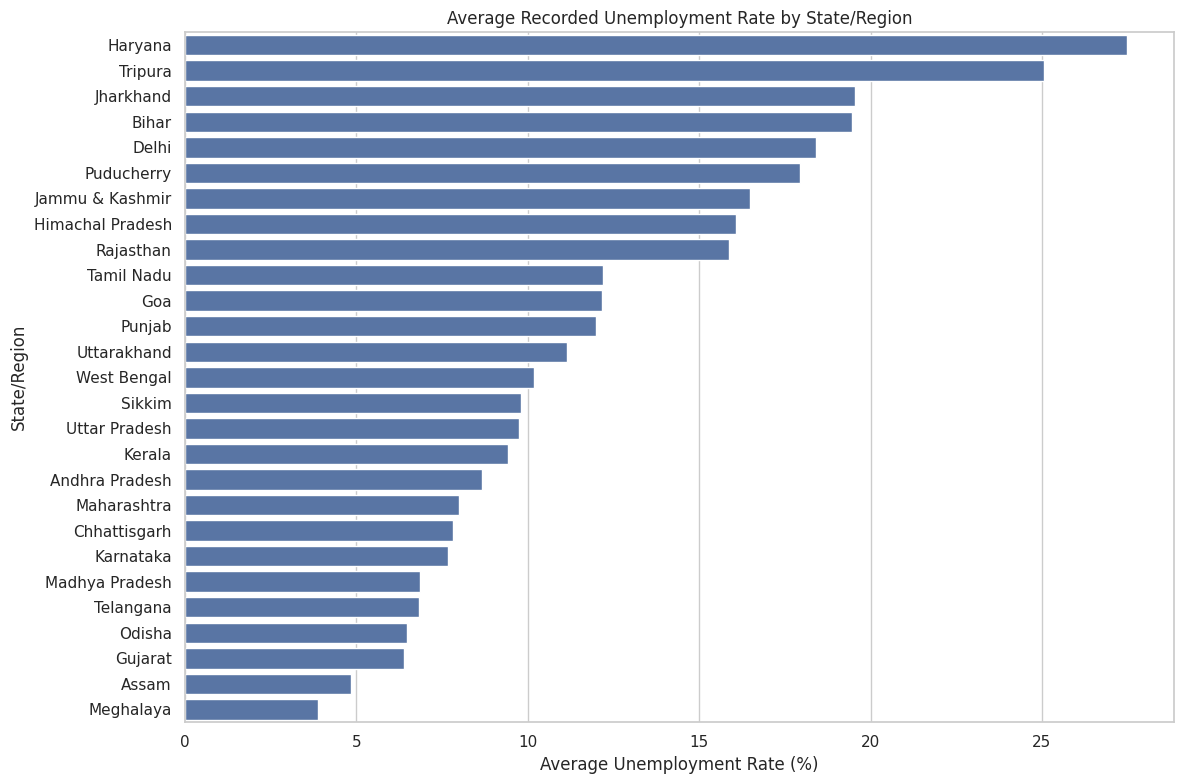

Highest recorded average rates in this dataset:


,Region,Estimated Unemployment Rate (%)
0,Haryana,27.48
1,Tripura,25.06
2,Jharkhand,19.54
3,Bihar,19.47
4,Delhi,18.41
5,Puducherry,17.94
6,Jammu & Kashmir,16.48
7,Himachal Pradesh,16.07
8,Rajasthan,15.87
9,Tamil Nadu,12.19


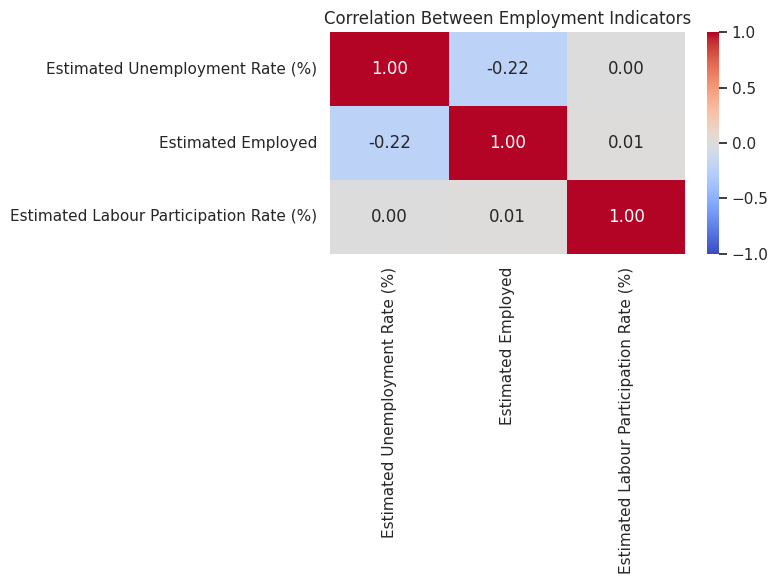

In [3]:
# ==========================================
# STEP 3: EXPLORATORY DATA ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Use the cleaned rural/urban dataset
df = df_area.copy()

# ------------------------------------------
# A. MONTHLY UNEMPLOYMENT TREND
# ------------------------------------------

monthly_trend = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_trend,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.title("India: Monthly Average Unemployment Rate")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------
# B. RURAL VS URBAN COMPARISON
# ------------------------------------------

area_comparison = (
    df.groupby("Area")["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=area_comparison,
    x="Area",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print("Rural/Urban comparison:")
display(area_comparison.round(2))


# ------------------------------------------
# C. STATE-LEVEL UNEMPLOYMENT RANKING
# ------------------------------------------

state_ranking = (
    df_states.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=state_ranking,
    x="Estimated Unemployment Rate (%)",
    y="Region"
)

plt.title("Average Recorded Unemployment Rate by State/Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State/Region")
plt.tight_layout()
plt.show()

print("Highest recorded average rates in this dataset:")
display(state_ranking.head(10).round(2))


# ------------------------------------------
# D. CORRELATION HEATMAP
# ------------------------------------------

correlation_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

In [4]:
# =====================================================
# STEP 4: COVID-19 IMPACT ANALYSIS
# =====================================================

import pandas as pd
import numpy as np
import plotly.express as px

# Use the cleaned rural/urban dataset
covid_df = df_area.copy()

# Ensure date column is datetime
covid_df["Date"] = pd.to_datetime(covid_df["Date"])

# Create a month column for grouping
covid_df["Month"] = covid_df["Date"].dt.to_period("M").dt.to_timestamp()

# Define comparison periods
covid_df["Period"] = np.select(
    [
        covid_df["Month"].between(
            pd.Timestamp("2020-01-01"),
            pd.Timestamp("2020-02-01")
        ),
        covid_df["Month"].between(
            pd.Timestamp("2020-04-01"),
            pd.Timestamp("2020-05-01")
        ),
        covid_df["Month"].eq(pd.Timestamp("2020-06-01"))
    ],
    [
        "Pre-lockdown (Jan-Feb 2020)",
        "Early lockdown (Apr-May 2020)",
        "June 2020 observation"
    ],
    default="Other"
)

# Focus on the comparison periods
comparison_df = covid_df[
    covid_df["Period"].isin([
        "Pre-lockdown (Jan-Feb 2020)",
        "Early lockdown (Apr-May 2020)"
    ])
].copy()

# Calculate average recorded unemployment by area and period
period_summary = (
    comparison_df.groupby(["Area", "Period"])
    ["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

print("AVERAGE RECORDED UNEMPLOYMENT BY PERIOD")
display(period_summary.round(2))

# Pivot periods into separate columns
impact_table = period_summary.pivot(
    index="Area",
    columns="Period",
    values="Estimated Unemployment Rate (%)"
)

# Calculate change in percentage points
pre_col = "Pre-lockdown (Jan-Feb 2020)"
lockdown_col = "Early lockdown (Apr-May 2020)"

impact_table["Change (percentage points)"] = (
    impact_table[lockdown_col] - impact_table[pre_col]
)

impact_table["Relative change (%)"] = (
    impact_table["Change (percentage points)"]
    / impact_table[pre_col].replace(0, np.nan)
) * 100

print("\nPRE-LOCKDOWN VS EARLY-LOCKDOWN COMPARISON")
display(impact_table.round(2))

# Interactive chart
fig = px.bar(
    period_summary,
    x="Area",
    y="Estimated Unemployment Rate (%)",
    color="Period",
    barmode="group",
    title="Recorded Unemployment Before and During Early COVID-19 Lockdowns",
    labels={
        "Area": "Area",
        "Estimated Unemployment Rate (%)": "Unemployment rate (%)",
        "Period": "Comparison period"
    },
    color_discrete_sequence=["#2563EB", "#F97316"]
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    legend_title_text="Period",
    height=550
)

fig.show()

# Interactive monthly trend by area
monthly_area = (
    covid_df.groupby(["Month", "Area"])
    ["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

fig = px.line(
    monthly_area,
    x="Month",
    y="Estimated Unemployment Rate (%)",
    color="Area",
    markers=True,
    title="Monthly Unemployment Trends: Rural vs Urban",
    labels={
        "Month": "Month",
        "Estimated Unemployment Rate (%)": "Unemployment rate (%)",
        "Area": "Area"
    },
    color_discrete_sequence=["#0F766E", "#9333EA"]
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=550
)

fig.show()

AVERAGE RECORDED UNEMPLOYMENT BY PERIOD


,Area,Period,Estimated Unemployment Rate (%)
0,Rural,Early lockdown (Apr-May 2020),21.48
1,Rural,Pre-lockdown (Jan-Feb 2020),8.30
2,Urban,Early lockdown (Apr-May 2020),26.93
3,Urban,Pre-lockdown (Jan-Feb 2020),11.56



PRE-LOCKDOWN VS EARLY-LOCKDOWN COMPARISON


Period,Early lockdown (Apr-May 2020),Pre-lockdown (Jan-Feb 2020),Change (percentage points),Relative change (%)
Area,,,,
Rural,21.48,8.30,13.18,158.85
Urban,26.93,11.56,15.38,133.04


In [5]:
import pandas as pd
import numpy as np
import plotly.express as px
from IPython.display import display, Markdown

# Prepare a copy of the cleaned dataset
dashboard_df = df_area.copy()

# Create monthly dates
dashboard_df["Month"] = (
    dashboard_df["Date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calculate monthly averages by area
monthly_summary = (
    dashboard_df.groupby(["Month", "Area"], as_index=False)
    ["Estimated Unemployment Rate (%)"]
    .mean()
)

# Calculate overall dataset-level metrics
overall_rate = dashboard_df[
    "Estimated Unemployment Rate (%)"
].mean()

rural_rate = dashboard_df.loc[
    dashboard_df["Area"].str.strip().str.lower() == "rural",
    "Estimated Unemployment Rate (%)"
].mean()

urban_rate = dashboard_df.loc[
    dashboard_df["Area"].str.strip().str.lower() == "urban",
    "Estimated Unemployment Rate (%)"
].mean()

highest_region = (
    dashboard_df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Display dashboard heading
display(Markdown("""
# 🇮🇳 Unemployment Analysis in India
### Interactive Data Science Dashboard
**Focus:** Unemployment trends, rural–urban differences, and the COVID-19 period.
"""))

# Display summary metrics
metrics = pd.DataFrame({
    "Metric": [
        "Average recorded unemployment",
        "Rural average",
        "Urban average"
    ],
    "Rate (%)": [
        round(overall_rate, 2),
        round(rural_rate, 2),
        round(urban_rate, 2)
    ]
})

display(metrics)

# Chart 1: Monthly trend
fig1 = px.line(
    monthly_summary,
    x="Month",
    y="Estimated Unemployment Rate (%)",
    color="Area",
    markers=True,
    title="Monthly Unemployment Trends: Rural vs Urban",
    template="plotly_white"
)

fig1.update_layout(
    title_x=0.5,
    height=500,
    hovermode="x unified"
)

fig1.show()

# Chart 2: Average unemployment by region
region_summary = (
    dashboard_df.groupby("Region", as_index=False)
    ["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values("Estimated Unemployment Rate (%)", ascending=False)
)

fig2 = px.bar(
    region_summary,
    x="Region",
    y="Estimated Unemployment Rate (%)",
    title="Average Recorded Unemployment by Region",
    template="plotly_white"
)

fig2.update_layout(
    title_x=0.5,
    height=600,
    xaxis_tickangle=-45
)

fig2.show()

# Chart 3: Employment vs unemployment
fig3 = px.scatter(
    dashboard_df,
    x="Estimated Employed",
    y="Estimated Unemployment Rate (%)",
    color="Area",
    hover_name="Region",
    title="Employment Estimates vs. Unemployment Rate",
    template="plotly_white"
)

fig3.update_layout(
    title_x=0.5,
    height=500
)

fig3.show()

# Show the five highest regional averages
display(Markdown("## 🔎 Five regions with the highest average recorded unemployment"))

display(highest_region.head(5).round(2).rename(
    "Average unemployment rate (%)"
).to_frame())

print("Dashboard analysis completed successfully!")


# 🇮🇳 Unemployment Analysis in India
### Interactive Data Science Dashboard
**Focus:** Unemployment trends, rural–urban differences, and the COVID-19 period.


,Metric,Rate (%)
0,Average recorded unemployment,11.79
1,Rural average,10.32
2,Urban average,13.17


## 🔎 Five regions with the highest average recorded unemployment

,Average unemployment rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54


Dashboard analysis completed successfully!
